In [1]:
from duckdb import sql

## 2. Stations table

Task: Put stations data into `stations` table in DuckDB.

This code creates the `stations` table from the downloaded stations CSV file.


In [2]:
sql("""
    CREATE TABLE IF NOT EXISTS stations as 
    SELECT * FROM "data/stations-2023-09.csv"
""")

## 3. Distances table

Task: Create the `distances` table from inter-station distance data.

This code loads the tariff distance matrix into DuckDB.


In [3]:
sql("""
    CREATE TABLE IF NOT EXISTS distances as
    SELECT * FROM "data/tariff-distances-2022-01.csv"
""")

## 3. Long distances table

Task: Create `distances_long` based on the DuckDB tutorial.

This code unpivots the distance matrix into station pairs with one `distance` value per row.


In [4]:
sql("""
    CREATE TABLE IF NOT EXISTS distances_long AS
        UNPIVOT distances
        ON COLUMNS (* EXCLUDE station)
        INTO NAME other_station VALUE distance;
""")

## 4. Disruptions table

Task: Put train disruptions into the Postgres `disruptions` table.

This code connects DuckDB to Postgres and loads disruption CSV files from 2011-2023.


In [5]:
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

sql("""INSTALL postgres; LOAD postgres;""")
sql(
    f"""ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db_rw (TYPE postgres, READ_WRITE);"""
)

sql(f"""
    CREATE TABLE IF NOT EXISTS postgres_db_rw.disruptions as
    FROM read_csv({["data/disruptions-" + str(year) + ".csv" for year in range(2011, 2024)]})
""")

## 5. Services Parquet file

Task: Transform train service CSV files into a single Parquet file.

This code reads service files from 2019-2025 and writes them as compressed Parquet.


In [6]:
sql(f"""
    COPY (SELECT * FROM read_csv({["data/services-" + str(year) + ".csv" for year in range(2019, 2026)]})) TO 'data/services.parquet' (COMPRESSION zstd);
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 5. Services table

Task: Make the `services` table from the Parquet file.

This code creates the DuckDB analytics table used by the following queries.


In [7]:
sql("""
    CREATE TABLE IF NOT EXISTS services as
    SELECT * FROM "data/services.parquet"
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [9]:
sql("describe services")

┌──────────────────────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │       column_type        │  null   │   key   │ default │  extra  │
│           varchar            │         varchar          │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼──────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE                     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN                  │ YES     │ NULL    │ NULL    │ NULL    │


## 7.1. Departures From Amsterdam Centraal

Question: How many trains departed from Amsterdam Central station overall?

This query counts departures from `Amsterdam Centraal` using non-null departure times.


In [10]:
sql("""
    SELECT COUNT("Stop:Departure time") from services where "Stop:Station name" LIKE 'Amsterdam Centraal';
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────────────┐
│ count("Stop:Departure time") │
│            int64             │
├──────────────────────────────┤
│                      1940873 │
└──────────────────────────────┘

## 7.2. Average Delay By Service Type

Question: Calculate the average arrival delay of different service types.

This query groups services by `Service:Type` and sorts them by average arrival delay.


In [11]:
sql("""
    SELECT AVG("Stop:Arrival delay"), "Service:Type" from services group by 2 order by 1 desc;
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────────┬──────────────────────┐
│ avg("Stop:Arrival delay") │     Service:Type     │
│          double           │       varchar        │
├───────────────────────────┼──────────────────────┤
│         31.84254143646409 │ Alpen Express        │
│        18.304347826086957 │ Krokus Express       │
│        14.262589044460821 │ European Sleeper     │
│          9.42391097403092 │ Nightjet             │
│          7.76692176533566 │ ICE                  │
│         7.302104678961749 │ Eurostar             │
│         5.482790573052148 │ ICE International    │
│        5.3961896909446025 │ Thalys               │
│         4.677560708417016 │ Int. Trein           │
│        3.8370501214396113 │ Nachttrein           │
│                        ·  │     ·                │
│                        ·  │     ·                │
│                        ·  │     ·                │
│                       0.0 │ Tram i.p.v. trein    │
│                       0.0 │ Snelbus i.p.v. t

In [12]:
sql("""
    describe postgres_db_rw.disruptions
""")

┌──────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name      │ column_type │  null   │   key   │ default │  extra  │
│       varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ rdt_id               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ns_lines             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines_id         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_names    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_codes    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_nl             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_en             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ statistical_cause_nl │ VARCHAR     │ YES     │ NUL

## 7.3. Most Common Disruption Cause By Year

Question: What was the most common disruption cause in different years?

This query uses `MODE(cause_en)` grouped by the year of `start_time`.


In [13]:
sql("""
    SELECT MODE(cause_en), YEAR(start_time) from postgres_db_rw.disruptions group by 2 order by 2;
""")

┌───────────────────┬────────────────────┐
│ "mode"(cause_en)  │ "year"(start_time) │
│      varchar      │       int64        │
├───────────────────┼────────────────────┤
│ broken down train │               2011 │
│ points failure    │               2012 │
│ points failure    │               2013 │
│ broken down train │               2014 │
│ broken down train │               2015 │
│ broken down train │               2016 │
│ broken down train │               2017 │
│ broken down train │               2018 │
│ broken down train │               2019 │
│ broken down train │               2020 │
│ broken down train │               2021 │
│ broken down train │               2022 │
│ broken down train │               2023 │
└───────────────────┴────────────────────┘
  13 rows                      2 columns

## 7.4. Services Starting In Amsterdam

Question: How many trains started their overall service in any Amsterdam station?

This query counts distinct services whose first stop is an Amsterdam station.


In [14]:
sql("""
    SELECT COUNT(DISTINCT "Service:RDT-ID") FROM services WHERE "Stop:Arrival time" IS NULL AND "Stop:Station name" LIKE 'Amsterdam%';
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────────────────┐
│ count(DISTINCT "Service:RDT-ID") │
│              int64               │
├──────────────────────────────────┤
│                          1277350 │
└──────────────────────────────────┘

## 7.5. Final Destinations Outside The Netherlands - Count

Question: What fraction of services was run to final destinations outside the Netherlands?

This helper query counts distinct services ending outside the Netherlands.


In [15]:
sql("""
    SELECT COUNT(DISTINCT "Service:RDT-ID") 
    FROM services INNER JOIN stations ON services."Stop:Station code" = stations."code" WHERE "Stop:Departure time" IS NULL AND stations."country" <> 'NL';
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────────────────┐
│ count(DISTINCT "Service:RDT-ID") │
│              int64               │
├──────────────────────────────────┤
│                           625461 │
└──────────────────────────────────┘

## 7.5. Final Destinations Outside The Netherlands - Fraction

Question: What fraction of services was run to final destinations outside the Netherlands?

This query divides services ending outside the Netherlands by all services with a final destination.


In [16]:
sql("""
    WITH total_services AS (
        SELECT COUNT(DISTINCT "Service:RDT-ID") AS total
        FROM services
        WHERE "Stop:Departure time" IS NULL )
    SELECT COUNT(DISTINCT "Service:RDT-ID")::DOUBLE / total_services.total as fraction_of_services_ending_outside_of_NL
    FROM services INNER JOIN stations ON services."Stop:Station code" = stations."code", total_services WHERE "Stop:Departure time" IS NULL AND stations."country" <> 'NL' group by total_services.total
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────────────────────────┐
│ fraction_of_services_ending_outside_of_NL │
│                  double                   │
├───────────────────────────────────────────┤
│                      0.037714929711991925 │
└───────────────────────────────────────────┘

## 7.6. Largest Distance Within The Netherlands

Question: What is the largest distance between stations in the Netherlands (`NL`)?

This query joins both station endpoints to `stations` and keeps only NL-NL station pairs.


In [17]:
sql("""
    select MAX(CAST(distance AS INT)) from distances_long 
    INNER JOIN stations as station_details ON distances_long."Station" = station_details."code" 
    INNER JOIN stations as other_station_details ON distances_long."other_station" = other_station_details."code" 
    WHERE station_details."country" = 'NL' AND other_station_details."country" = 'NL' AND distance <> 'XXX';
""")

┌────────────────────────────────┐
│ max(CAST(distance AS INTEGER)) │
│             int32              │
├────────────────────────────────┤
│                            426 │
└────────────────────────────────┘

## 7.7. Average Delay By Operator - Query

Question: Compare the average arrival delay between different train operators on a bar plot.

This query calculates average arrival delay per `Service:Company`.


In [18]:
delays = sql("""
    SELECT AVG("Stop:Arrival delay") as avg_arrival_delay, "Service:Company" as company from services WHERE "Stop:Arrival delay" IS NOT NULL group by 2 order by 1 desc;
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 7.7. Average Delay By Operator - Plot

This code draws the bar plot for average arrival delay by train operator.


Text(0, 0.5, 'Train operator')

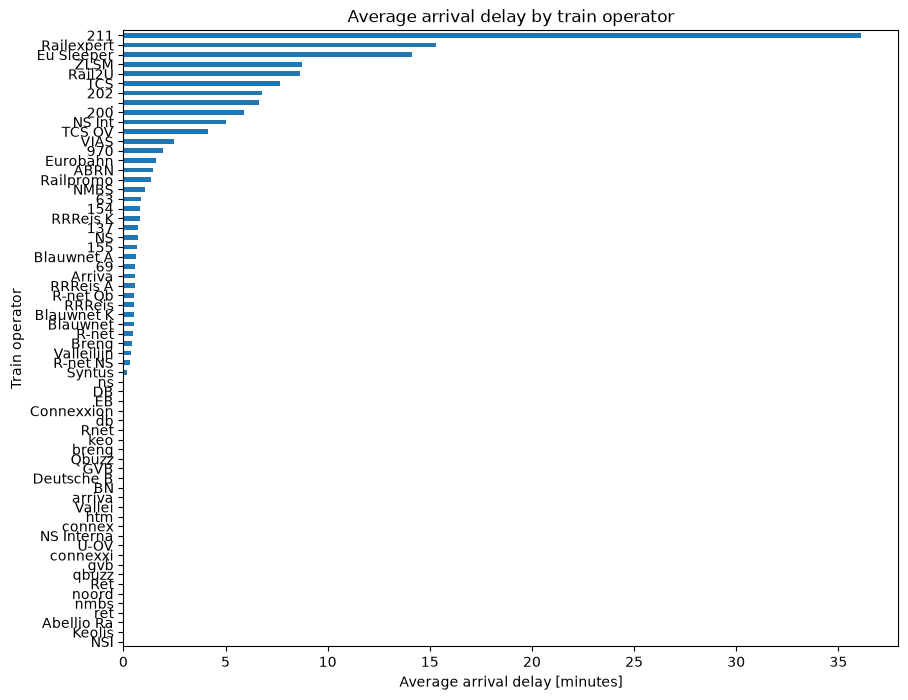

In [19]:
delays_sorted = delays.sort_values("avg_arrival_delay")

ax = delays_sorted.plot.barh(
    x="company",
    y="avg_arrival_delay",
    figsize=(10, 8),
    legend=False,
)

ax.set_title("Average arrival delay by train operator")
ax.set_xlabel("Average arrival delay [minutes]")
ax.set_ylabel("Train operator")

## 7.8. Disruptions By Year - Query

Question: How many services were disrupted in different years?

This query counts disruption records by year using the `disruptions` table.


In [20]:
disruptions_by_year = sql("""
    SELECT YEAR(start_time) AS year, COUNT(*) AS num_disruptions FROM postgres_db_rw.disruptions GROUP BY 1 ORDER BY 1
""")
disruptions_by_year

┌───────┬─────────────────┐
│ year  │ num_disruptions │
│ int64 │      int64      │
├───────┼─────────────────┤
│  2011 │            1846 │
│  2012 │            2074 │
│  2013 │            2312 │
│  2014 │            2484 │
│  2015 │            2947 │
│  2016 │            3031 │
│  2017 │            4085 │
│  2018 │            5190 │
│  2019 │            5940 │
│  2020 │            4450 │
│  2021 │            4874 │
│  2022 │            5499 │
│  2023 │            5168 │
└───────┴─────────────────┘
  13 rows       2 columns

In [21]:
disruptions_by_year = disruptions_by_year.df()

## 7.8. Disruptions By Year - Plot

This code draws the line plot of disruptions by year.


Text(0, 0.5, 'Number of disruptions')

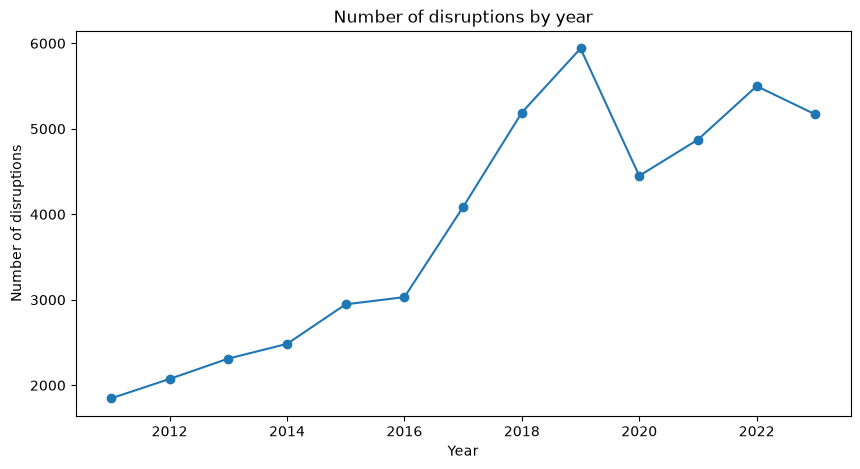

In [22]:
ax = disruptions_by_year.plot.line(
    x="year",
    y="num_disruptions",
    marker="o",
    figsize=(10, 5),
    legend=False,
)

ax.set_title("Number of disruptions by year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of disruptions")

## 7.9. Cancelled Services By Year - Query

Question: What fraction of all services were completely cancelled in different years?

This query calculates the cancellation fraction grouped by service year.


In [73]:
cancelled = sql("""
    WITH total_services AS (
        SELECT COUNT(DISTINCT "Service:RDT-ID") AS total,
        YEAR("Service:Date") AS YEAR
        FROM services
        group by year
        )
    SELECT COUNT(DISTINCT "Service:RDT-ID")::DOUBLE / total_services.total as cancelled_fraction, YEAR("Service:Date") as year
    FROM services INNER JOIN total_services ON YEAR(services."Service:Date") = total_services.year
    WHERE services."Service:Completely cancelled" IS TRUE
    GROUP by total, YEAR("Service:Date") ORDER BY year;
""")
cancelled

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────┬───────┐
│  cancelled_fraction  │ year  │
│        double        │ int64 │
├──────────────────────┼───────┤
│  0.01321224814191549 │  2019 │
│   0.0865804341349761 │  2020 │
│  0.04176223160350172 │  2021 │
│  0.06357165418513425 │  2022 │
│  0.05837845981662434 │  2023 │
│ 0.023108685960638427 │  2024 │
│ 0.021683422366413962 │  2025 │
└──────────────────────┴───────┘

## 7.9. Cancelled Services By Year - Plot

This code draws the line plot of completely cancelled service fraction by year.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

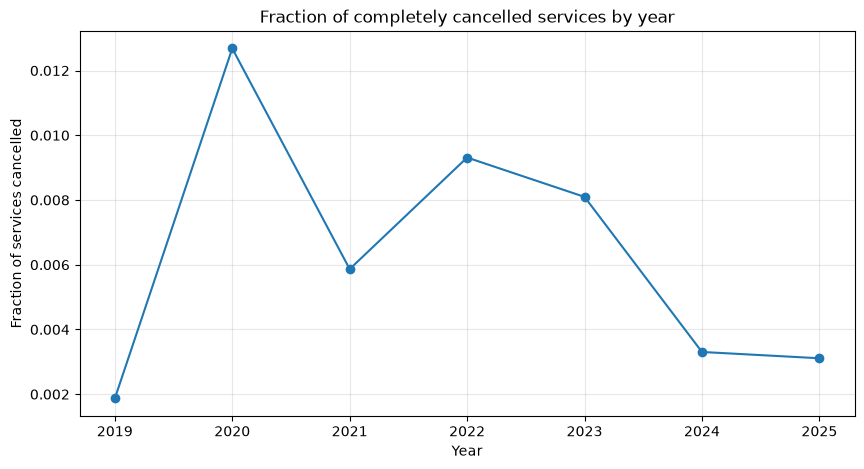

In [24]:
cancelled = cancelled.df()

ax = cancelled.plot.line(
    x="year",
    y="cancelled_fraction",
    marker="o",
    figsize=(10, 5),
    legend=False,
)

ax.set_title("Fraction of completely cancelled services by year")
ax.set_xlabel("Year")
ax.set_ylabel("Fraction of services cancelled")
ax.grid(True, alpha=0.3)

## 8.1. Service Stop Ordering

Task: Prepare service lengths using consecutive station pairs.

This helper cell inspects the `services` schema before building station-to-station connections.


In [25]:
sql("""
    describe services;
""")

┌──────────────────────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │       column_type        │  null   │   key   │ default │  extra  │
│           varchar            │         varchar          │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼──────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE                     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN                  │ YES     │ NULL    │ NULL    │ NULL    │


## 8.2. Station Connections Table

Task: Create `station_connections` with `Service:RDT-ID`, `start_station_code`, `end_station_code`, and distance.

This query uses `LEAD()` to pair each stop with the next stop in the same service, then joins those station pairs to `distances_long`.


In [76]:
sql("""
SELECT *
FROM distances_long
WHERE ("Station" = 'STV' AND other_station = 'VS')
   OR ("Station" = 'VS' AND other_station = 'STV');
   """)

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │ varchar  │
├─────────┼───────────────┼──────────┤
│ STV     │ VS            │ 421      │
│ VS      │ STV           │ 421      │
└─────────┴───────────────┴──────────┘

In [77]:
sql("""
CREATE OR REPLACE TABLE station_connections AS
with connections as (
    SELECT "Service:RDT-ID", "Stop:Station code" as start_station_code, 
    LEAD("Stop:Station code") OVER (partition by "Service:RDT-ID" ORDER BY "Stop:Departure time" NULLS LAST) as end_station_code
    from services)
    select 
        DISTINCT LEAST(start_station_code, end_station_code) AS start_station_code, 
        GREATEST(start_station_code, end_station_code) as end_station_code, 
        distances_long.distance::INT as distance
        from connections INNER JOIN distances_long ON start_station_code = Station AND end_station_code = other_station
        order by 3 desc
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 8.3. Largest Distance Between Consecutive Stations

Question: What is the largest distance between a pair of stations?

This query selects the longest station-to-station connection from `station_connections`.


In [78]:
sql("""
    select * from station_connections order by distance desc LIMIT 1
""")

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int32   │
├────────────────────┼──────────────────┼──────────┤
│ STV                │ VS               │      421 │
└────────────────────┴──────────────────┴──────────┘

## 8.4. Histogram Of Inter-Station Distances

Question: Plot a histogram of inter-station distances run by trains.

This code loads distances from `station_connections` and plots their distribution.


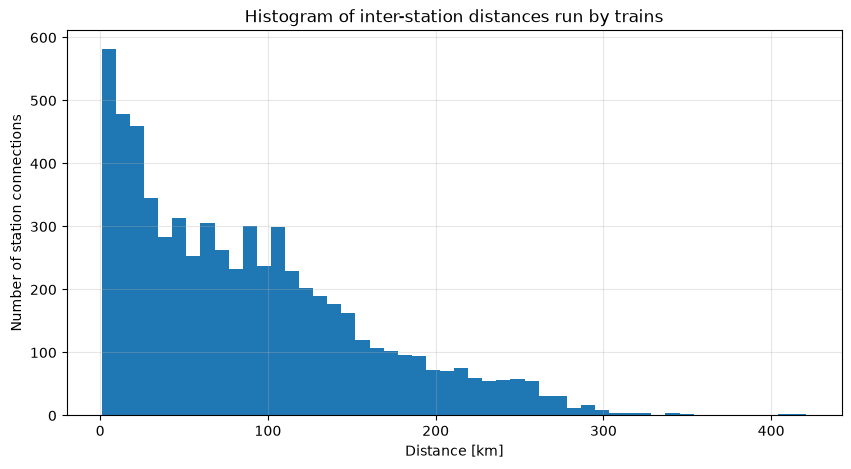

In [79]:
station_distances = sql("""
    SELECT distance
    FROM station_connections
    WHERE distance IS NOT NULL
""").df()

ax = station_distances.plot.hist(
    column="distance",
    bins=50,
    figsize=(10, 5),
    legend=False,
)

ax.set_title("Histogram of inter-station distances run by trains")
ax.set_xlabel("Distance [km]")
ax.set_ylabel("Number of station connections")
ax.grid(True, alpha=0.3)